In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

DATA_DIR = Path("/internmo internship projects/project 2")
OUTPUT_DIR = Path("phase2_outputs")
CHART_DIR = OUTPUT_DIR / "charts"

CHART_DIR.mkdir(parents=True, exist_ok=True)

print("Phase 2 environment ready!")

Phase 2 environment ready!


In [4]:
file_names = [
    "customers.csv",
    "subscriptions.csv",
    "plans.csv",
    "usage_data.csv",
    "network_quality.csv",
    "complaints.csv",
    "retention_campaigns.csv",
    "billing.csv"
]

data = {}

for file in file_names:
    path = DATA_DIR / file

    if path.exists():
        name = path.stem
        data[name] = pd.read_csv(path, low_memory=False)
        print(f"{name}: {data[name].shape}")
    else:
        print(f"File not found: {file}")

customers = data.get("customers", pd.DataFrame())
subscriptions = data.get("subscriptions", pd.DataFrame())
plans = data.get("plans", pd.DataFrame())
usage_data = data.get("usage_data", pd.DataFrame())
network_quality = data.get("network_quality", pd.DataFrame())
complaints = data.get("complaints", pd.DataFrame())
retention_campaigns = data.get("retention_campaigns", pd.DataFrame())
billing = data.get("billing", pd.DataFrame())

customers: (19076, 25)
subscriptions: (20523, 8)
plans: (25, 10)
usage_data: (57000, 5)
network_quality: (57000, 8)
complaints: (16584, 7)
retention_campaigns: (6475, 8)
billing: (115313, 9)


In [5]:
def find_col(df, candidates):
    """Return the first matching column name."""
    for col in candidates:
        if col in df.columns:
            return col
    return None


def to_numeric_col(df, column):
    """Convert a column to numeric without changing the original data."""
    if column is None:
        return pd.Series(np.nan, index=df.index)
    return pd.to_numeric(df[column], errors="coerce")


def save_chart(filename):
    plt.tight_layout()
    plt.savefig(CHART_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


customer_id_col = find_col(customers, ["customer_id"])
status_col = find_col(customers, ["customer_status", "churn_status", "status"])
segment_col = find_col(customers, ["customer_segment", "segment"])
tenure_col = find_col(customers, ["tenure_months", "tenure"])
city_tier_col = find_col(customers, ["city_tier"])
state_col = find_col(customers, ["state_name", "state", "state_id"])
product_col = find_col(customers, ["product_line"])

print("Customer columns:")
print({
    "customer_id": customer_id_col,
    "status": status_col,
    "segment": segment_col,
    "tenure": tenure_col,
    "city_tier": city_tier_col,
    "state": state_col,
    "product_line": product_col
})

if customers.empty or customer_id_col is None or status_col is None:
    raise ValueError(
        "customers.csv mein customer_id ya customer_status column nahi mila. "
        "Cell 4 ke output ke according column names update karo."
    )

# Standardize status labels for analysis.
customers_eda = customers.copy()
customers_eda["_status"] = (
    customers_eda[status_col].astype("string").str.strip().str.lower()
)
customers_eda["_churned"] = customers_eda["_status"].eq("churned")
customers_eda["_active"] = customers_eda["_status"].eq("active")

print("Customer rows:", len(customers_eda))
print("Churned customers:", int(customers_eda["_churned"].sum()))
print("Active customers:", int(customers_eda["_active"].sum()))

Customer columns:
{'customer_id': 'customer_id', 'status': 'customer_status', 'segment': 'customer_segment', 'tenure': 'tenure_months', 'city_tier': 'city_tier', 'state': 'state_id', 'product_line': 'product_line'}
Customer rows: 19076
Churned customers: 3516
Active customers: 15560


Total customers: 19,076
Churned customers: 3,516
Active customers: 15,560
Overall churn rate: 18.43%


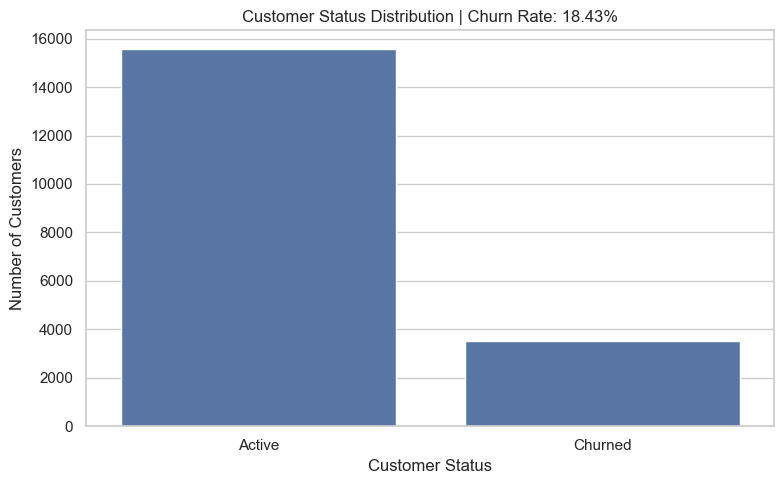

In [6]:
total_customers = len(customers_eda)
churned_count = int(customers_eda["_churned"].sum())
active_count = int(customers_eda["_active"].sum())

churn_rate = (
    churned_count / total_customers * 100
    if total_customers else 0
)

print(f"Total customers: {total_customers:,}")
print(f"Churned customers: {churned_count:,}")
print(f"Active customers: {active_count:,}")
print(f"Overall churn rate: {churn_rate:.2f}%")

plt.figure(figsize=(8, 5))

sns.barplot(
    x=["Active", "Churned"],
    y=[active_count, churned_count]
)

plt.title(f"Customer Status Distribution | Churn Rate: {churn_rate:.2f}%")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

save_chart("01_overall_churn.png")

,billing_cycle,customers,churned,churn_rate_percent
0,Annual,5320,427,8.026316
1,Monthly,14266,3342,23.426328


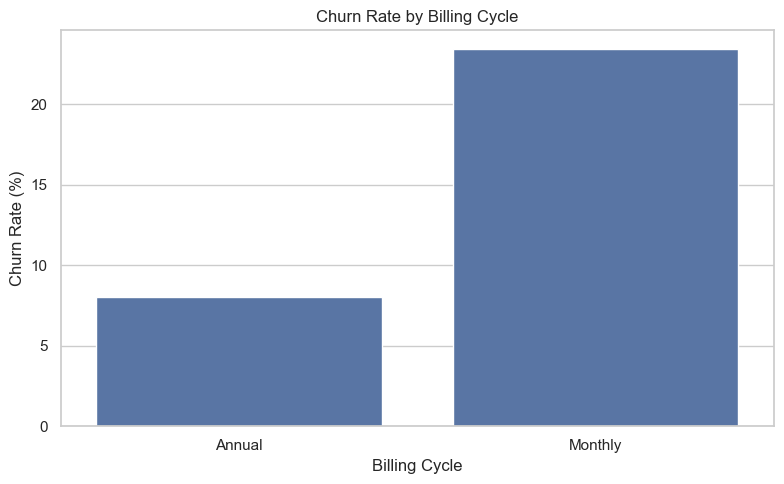

In [7]:
cycle_col = find_col(
    subscriptions,
    ["billing_cycle", "billing_frequency"]
)

sub_customer_col = find_col(subscriptions, ["customer_id"])

if cycle_col and sub_customer_col:
    cycle_data = subscriptions[[sub_customer_col, cycle_col]].copy()

    cycle_data = cycle_data.merge(
        customers_eda[[customer_id_col, "_churned"]],
        left_on=sub_customer_col,
        right_on=customer_id_col,
        how="left"
    )

    cycle_data = cycle_data.dropna(subset=[cycle_col, "_churned"])
    cycle_data[cycle_col] = cycle_data[cycle_col].astype(str).str.strip()

    cycle_summary = (
        cycle_data.groupby(cycle_col)
        .agg(
            customers=(sub_customer_col, "nunique"),
            churned=("_churned", "sum")
        )
        .reset_index()
    )

    cycle_summary["churn_rate_percent"] = (
        cycle_summary["churned"] /
        cycle_summary["customers"].replace(0, np.nan) * 100
    )

    display(cycle_summary)

    plt.figure(figsize=(8, 5))
    sns.barplot(
        data=cycle_summary,
        x=cycle_col,
        y="churn_rate_percent"
    )

    plt.title("Churn Rate by Billing Cycle")
    plt.xlabel("Billing Cycle")
    plt.ylabel("Churn Rate (%)")

    save_chart("02_churn_by_billing_cycle.png")
else:
    print("Subscriptions table mein billing_cycle ya customer_id column nahi mila.")

,tenure_band,customers,churned,churn_rate_percent
0,0–3 months,750,562,74.933333
1,4–12 months,1455,760,52.233677
2,13–36 months,2841,1028,36.184442
3,36+ months,14030,1166,8.310763


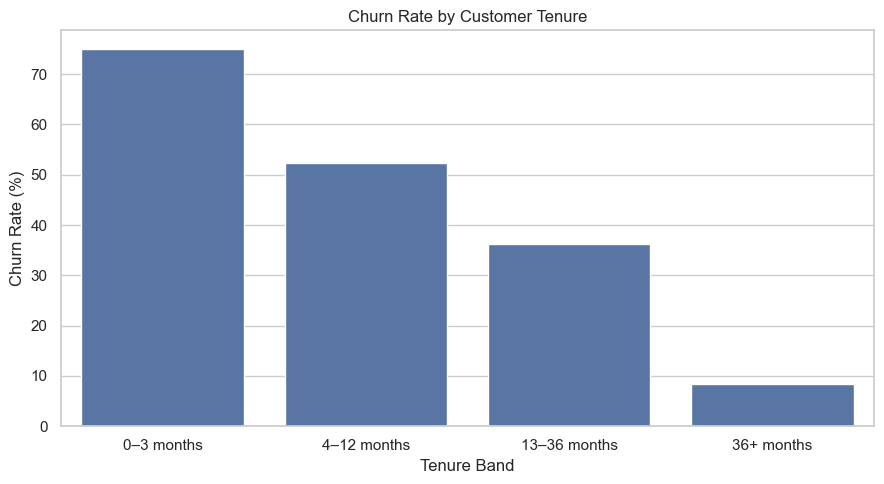

In [8]:
if tenure_col:
    tenure_data = customers_eda.copy()
    tenure_data["_tenure"] = to_numeric_col(
        tenure_data, tenure_col
    )

    tenure_data = tenure_data.dropna(subset=["_tenure"])

    tenure_data["tenure_band"] = pd.cut(
        tenure_data["_tenure"],
        bins=[-np.inf, 3, 12, 36, np.inf],
        labels=["0–3 months", "4–12 months", "13–36 months", "36+ months"]
    )

    tenure_summary = (
        tenure_data.groupby("tenure_band", observed=False)
        .agg(
            customers=("_churned", "size"),
            churned=("_churned", "sum")
        )
        .reset_index()
    )

    tenure_summary["churn_rate_percent"] = (
        tenure_summary["churned"] /
        tenure_summary["customers"].replace(0, np.nan) * 100
    )

    display(tenure_summary)

    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=tenure_summary,
        x="tenure_band",
        y="churn_rate_percent"
    )

    plt.title("Churn Rate by Customer Tenure")
    plt.xlabel("Tenure Band")
    plt.ylabel("Churn Rate (%)")

    save_chart("03_churn_by_tenure.png")
else:
    print("Customer tenure column nahi mila.")

,complaint_band,customers,churned,churn_rate_percent
0,0,12996,1962,15.096953
1,1,4951,1156,23.348818
2,2,978,325,33.231084
3,3+,151,73,48.344371


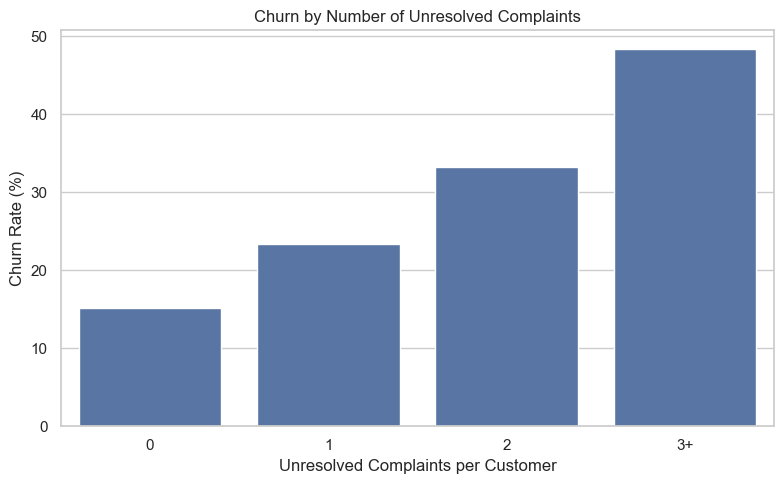

In [9]:
complaint_customer_col = find_col(
    complaints, ["customer_id"]
)
complaint_status_col = find_col(
    complaints, ["status", "complaint_status"]
)

if complaint_customer_col and complaint_status_col:

    complaint_work = complaints.copy()

    complaint_work["_complaint_status"] = (
        complaint_work[complaint_status_col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    unresolved = complaint_work[
        complaint_work["_complaint_status"] == "unresolved"
    ]

    unresolved_counts = (
        unresolved.groupby(complaint_customer_col)
        .size()
        .rename("unresolved_complaints")
        .reset_index()
    )

    complaint_analysis = customers_eda.merge(
        unresolved_counts,
        left_on=customer_id_col,
        right_on=complaint_customer_col,
        how="left"
    )

    complaint_analysis["unresolved_complaints"] = (
        complaint_analysis["unresolved_complaints"]
        .fillna(0)
        .astype(int)
    )

    complaint_analysis["complaint_band"] = pd.cut(
        complaint_analysis["unresolved_complaints"],
        bins=[-1, 0, 1, 2, np.inf],
        labels=["0", "1", "2", "3+"]
    )

    complaint_summary = (
        complaint_analysis.groupby("complaint_band", observed=False)
        .agg(
            customers=("_churned", "size"),
            churned=("_churned", "sum")
        )
        .reset_index()
    )

    complaint_summary["churn_rate_percent"] = (
        complaint_summary["churned"] /
        complaint_summary["customers"].replace(0, np.nan) * 100
    )

    display(complaint_summary)

    plt.figure(figsize=(8, 5))
    sns.barplot(
        data=complaint_summary,
        x="complaint_band",
        y="churn_rate_percent"
    )

    plt.title("Churn by Number of Unresolved Complaints")
    plt.xlabel("Unresolved Complaints per Customer")
    plt.ylabel("Churn Rate (%)")

    save_chart("04_churn_by_unresolved_complaints.png")
else:
    print("Complaints mein customer_id ya status column nahi mila.")

,customer_segment,customers,churned,churn_rate_percent
1,Mass,2943,787,26.74142
3,Value,6216,1277,20.543758
2,Premium,8521,1286,15.092125
0,Enterprise,1396,166,11.891117


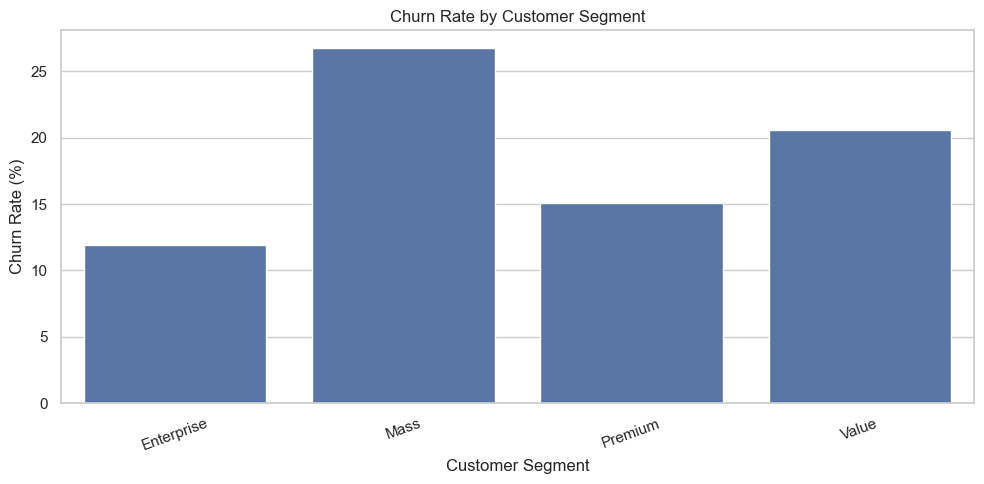

In [10]:
if segment_col:

    segment_summary = (
        customers_eda.groupby(segment_col, dropna=False)
        .agg(
            customers=("_churned", "size"),
            churned=("_churned", "sum")
        )
        .reset_index()
    )

    segment_summary["churn_rate_percent"] = (
        segment_summary["churned"] /
        segment_summary["customers"].replace(0, np.nan) * 100
    )

    display(segment_summary.sort_values(
        "churn_rate_percent", ascending=False
    ))

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=segment_summary,
        x=segment_col,
        y="churn_rate_percent"
    )

    plt.title("Churn Rate by Customer Segment")
    plt.xlabel("Customer Segment")
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=20)

    save_chart("05_churn_by_segment.png")
else:
    print("customer_segment column nahi mila.")

,state_id,total_customers,churned_customers,churn_rate_percent
9,ST010,1887,305,16.163222
3,ST004,1662,285,17.148014
14,ST016,1509,281,18.621604
4,ST005,1343,246,18.3172
13,ST015,1169,223,19.076133
10,ST011,1134,192,16.931217
11,ST012,989,182,18.402427
15,ST017,863,162,18.771727
16,ST018,834,160,19.184652
18,ST022,821,157,19.123021


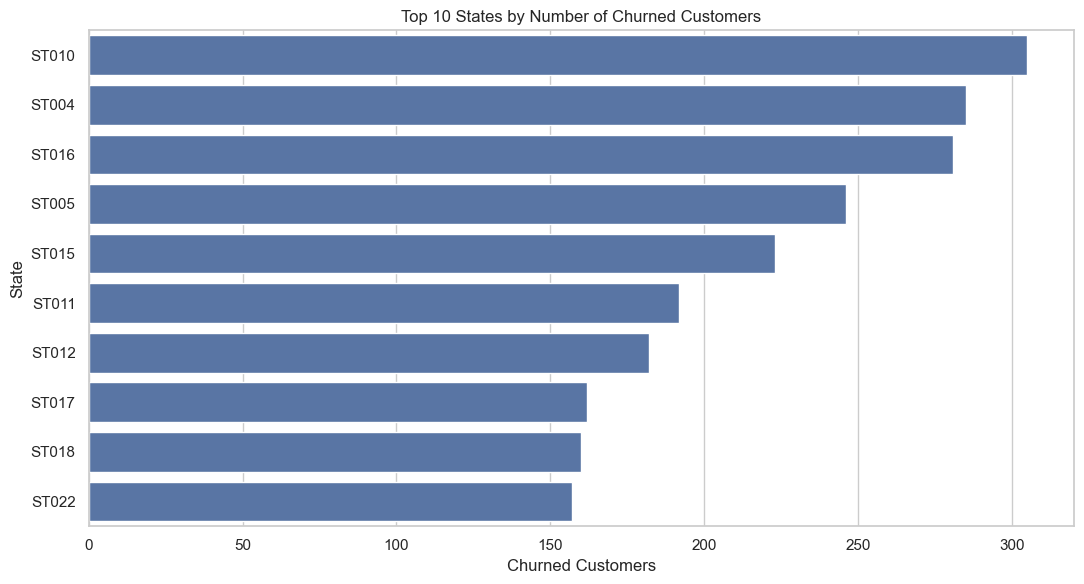

In [11]:
if state_col:

    state_data = customers_eda.dropna(subset=[state_col])

    state_summary = (
        state_data.groupby(state_col)
        .agg(
            total_customers=("_churned", "size"),
            churned_customers=("_churned", "sum")
        )
        .reset_index()
    )

    state_summary["churn_rate_percent"] = (
        state_summary["churned_customers"] /
        state_summary["total_customers"].replace(0, np.nan) * 100
    )

    top_states = (
        state_summary.sort_values(
            "churned_customers", ascending=False
        ).head(10)
    )

    display(top_states)

    plt.figure(figsize=(11, 6))

    sns.barplot(
        data=top_states,
        y=state_col,
        x="churned_customers"
    )

    plt.title("Top 10 States by Number of Churned Customers")
    plt.xlabel("Churned Customers")
    plt.ylabel("State")

    save_chart("06_top10_states_by_churn.png")
else:
    print("State column nahi mila. Available columns:", customers.columns.tolist())

,city_tier,average_data_gb,customer_count
0,Metro,49.189585,4859
1,Tier-2,41.753071,9211
2,Tier-3,28.379936,4930


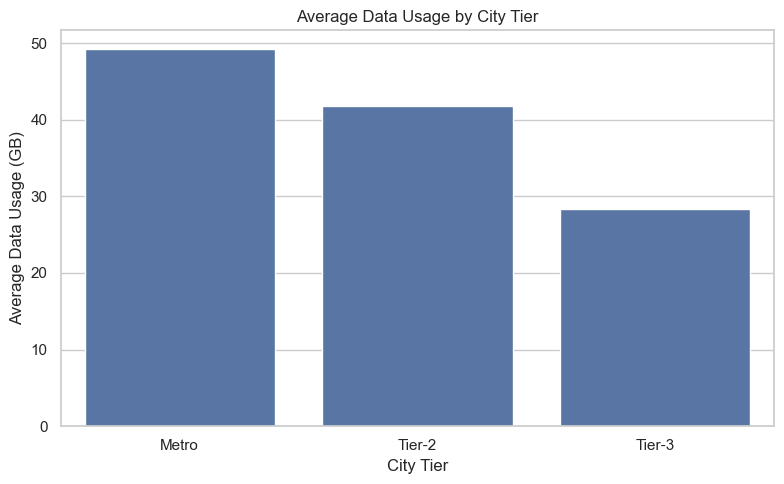

In [12]:
usage_customer_col = find_col(usage_data, ["customer_id"])
usage_col = find_col(usage_data, ["data_gb_used"])

if (
    usage_customer_col
    and usage_col
    and customer_id_col
    and city_tier_col
):

    usage_values = usage_data[
        [usage_customer_col, usage_col]
    ].copy()

    usage_values[usage_col] = pd.to_numeric(
        usage_values[usage_col], errors="coerce"
    )

    customer_tiers = customers_eda[
        [customer_id_col, city_tier_col]
    ].drop_duplicates(subset=[customer_id_col])

    usage_with_tier = usage_values.merge(
        customer_tiers,
        left_on=usage_customer_col,
        right_on=customer_id_col,
        how="inner"
    )

    usage_summary = (
        usage_with_tier.groupby(city_tier_col)
        .agg(
            average_data_gb=(usage_col, "mean"),
            customer_count=(usage_customer_col, "nunique")
        )
        .reset_index()
    )

    display(usage_summary)

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=usage_summary,
        x=city_tier_col,
        y="average_data_gb"
    )

    plt.title("Average Data Usage by City Tier")
    plt.xlabel("City Tier")
    plt.ylabel("Average Data Usage (GB)")

    save_chart("07_average_data_usage_by_city_tier.png")
else:
    print("Usage ya customer table mein required columns nahi mile.")

Valid charge records: 20523
Average monthly charge: ₹842.26
Median monthly charge: ₹499.00


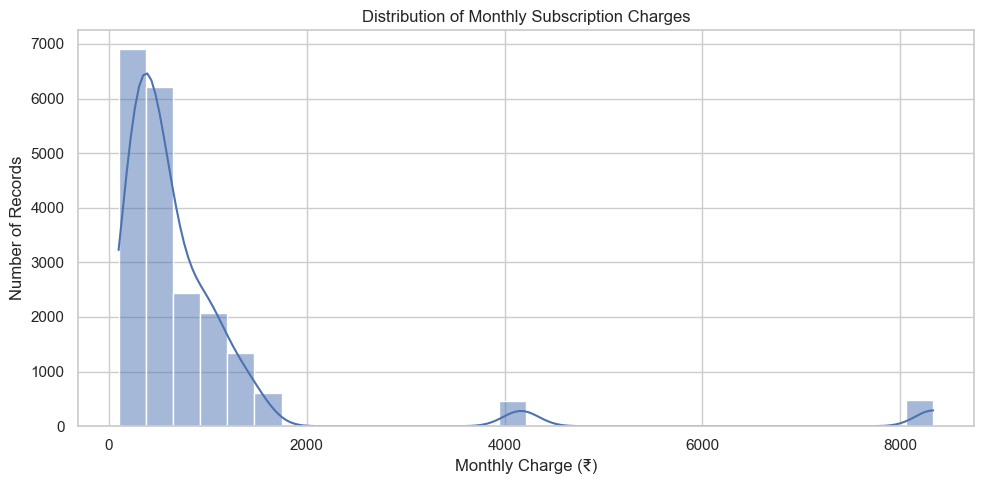

In [13]:
charge_col = find_col(
    subscriptions,
    ["monthly_charge_inr", "monthly_charge", "monthly_amount"]
)

if charge_col:

    monthly_charges = pd.to_numeric(
        subscriptions[charge_col], errors="coerce"
    ).dropna()

    print("Valid charge records:", len(monthly_charges))
    print(f"Average monthly charge: ₹{monthly_charges.mean():,.2f}")
    print(f"Median monthly charge: ₹{monthly_charges.median():,.2f}")

    plt.figure(figsize=(10, 5))

    sns.histplot(
        monthly_charges,
        bins=30,
        kde=True
    )

    plt.title("Distribution of Monthly Subscription Charges")
    plt.xlabel("Monthly Charge (₹)")
    plt.ylabel("Number of Records")

    save_chart("08_monthly_charge_distribution.png")
else:
    print("Subscriptions table mein monthly charge column nahi mila.")

In [15]:
network_customer_col = find_col(
    network_quality, ["customer_id"]
)

drop_col = find_col(
    network_quality,
    ["dropped_call_rate", "drop_call_rate", "call_drop_rate"]
)

if network_customer_col and drop_col:

    network_work = network_quality[
        [network_customer_col, drop_col]
    ].copy()

    network_work[drop_col] = pd.to_numeric(
        network_work[drop_col], errors="coerce"
    )

    # Multiple monthly records ko customer-level average mein convert karo.
    network_customer = (
        network_work.groupby(network_customer_col)[drop_col]
        .mean()
        .reset_index()
    )

    network_analysis = network_customer.merge(
        customers_eda[
            [customer_id_col, "_churned"]
        ],
        left_on=network_customer_col,
        right_on=customer_id_col,
        how="inner"
    )

    display(
        network_analysis.groupby("_churned")[drop_col]
        .agg(["count", "mean", "median"])
        .rename(index={False: "Active", True: "Churned"})
    )

    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=network_analysis,
        x="_churned",
        y=drop_col
    )

    plt.xticks([0, 1], ["Active", "Churned"])
    plt.title("Dropped-Call Rate vs Customer Churn")
    plt.xlabel("Customer Status")
    plt.ylabel("Average Dropped-Call Rate")

    save_chart("09_network_quality_vs_churn.png")
else:
    print(
        "Dropped-call rate ya customer_id column nahi mila. "
        "Available columns:",
        network_quality.columns.tolist()
    )

Dropped-call rate ya customer_id column nahi mila. Available columns: ['record_id', 'customer_id', 'city_id', 'month', 'avg_signal_strength_dbm', 'dropped_call_rate_pct', 'avg_download_speed_mbps', 'network_downtime_hours']


In [16]:
campaign_customer_col = find_col(
    retention_campaigns,
    ["customer_id"]
)

outcome_col = find_col(
    retention_campaigns,
    ["campaign_outcome", "outcome", "response_status", "status"]
)

if outcome_col:

    campaign_work = retention_campaigns.copy()

    campaign_work["_outcome"] = (
        campaign_work[outcome_col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    print("Unique campaign outcomes:")
    print(campaign_work["_outcome"].value_counts(dropna=False))

    outcome_summary = (
        campaign_work["_outcome"]
        .fillna("unknown")
        .value_counts()
        .rename_axis("outcome")
        .reset_index(name="campaign_records")
    )

    display(outcome_summary)

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=outcome_summary,
        x="outcome",
        y="campaign_records"
    )

    plt.title("Retention Campaign Outcomes")
    plt.xlabel("Campaign Outcome")
    plt.ylabel("Number of Campaign Records")
    plt.xticks(rotation=25)

    save_chart("10_retention_campaign_outcomes.png")

    # Estimate retained share only if a retention-result column exists.
    retained_col = find_col(
        campaign_work,
        ["retained", "customer_retained", "retention_success"]
    )

    if retained_col:
        retained_values = (
            campaign_work[retained_col]
            .astype("string")
            .str.strip()
            .str.lower()
        )

        retained_mask = retained_values.isin(
            ["yes", "true", "1", "retained"]
        )

        valid_mask = retained_values.isin(
            ["yes", "true", "1", "retained",
             "no", "false", "0", "not retained"]
        )

        retained_share = (
            retained_mask[valid_mask].mean() * 100
            if valid_mask.any() else np.nan
        )

        print(f"Retained share: {retained_share:.2f}%")
    else:
        print(
            "Dedicated retention-result column nahi mila. "
            "Retained share ko reliably calculate karne ke liye "
            "actual retention outcome field verify karna hoga."
        )
else:
    print(
        "Campaign outcome column nahi mila. "
        "Available columns:",
        retention_campaigns.columns.tolist()
    )

Campaign outcome column nahi mila. Available columns: ['campaign_id', 'customer_id', 'campaign_name', 'offer_type', 'contact_date', 'channel', 'response', 'retained_flag']


In [17]:
print("Charts saved in:", CHART_DIR.resolve())

chart_files = sorted(CHART_DIR.glob("*.png"))

print("Total charts generated:", len(chart_files))

for chart in chart_files:
    print(chart.name)

Charts saved in: D:\internmo internship projects\project 2\phase2_outputs\charts
Total charts generated: 8
01_overall_churn.png
02_churn_by_billing_cycle.png
03_churn_by_tenure.png
04_churn_by_unresolved_complaints.png
05_churn_by_segment.png
06_top10_states_by_churn.png
07_average_data_usage_by_city_tier.png
08_monthly_charge_distribution.png


In [18]:
summary_path = OUTPUT_DIR / "Phase2_EDA_Summary.txt"

summary_text = f"""
NexaTel Customer Churn Analytics
Phase 2: Exploratory Data Analysis

Total customers: {len(customers_eda):,}
Churned customers: {int(customers_eda['_churned'].sum()):,}
Active customers: {int(customers_eda['_active'].sum()):,}
Overall churn rate: {churn_rate:.2f}%

Charts folder: {CHART_DIR.resolve()}

Charts planned:
1. Overall churn rate
2. Churn by billing cycle
3. Churn by tenure band
4. Churn by unresolved complaints
5. Churn by customer segment
6. Top 10 states by churned customers
7. Average data usage by city tier
8. Monthly subscription charge distribution
9. Network quality vs churn
10. Retention campaign outcomes

Review each chart and document 2-3 sentences of
observations based on the actual dataset results.

Note: Charts may be skipped if required columns are absent.
Verify the generated PNG files before submission.
"""

summary_path.write_text(summary_text, encoding="utf-8")

print(summary_text)
print("Summary saved:", summary_path.resolve())


NexaTel Customer Churn Analytics
Phase 2: Exploratory Data Analysis

Total customers: 19,076
Churned customers: 3,516
Active customers: 15,560
Overall churn rate: 18.43%

Charts folder: D:\internmo internship projects\project 2\phase2_outputs\charts

Charts planned:
1. Overall churn rate
2. Churn by billing cycle
3. Churn by tenure band
4. Churn by unresolved complaints
5. Churn by customer segment
6. Top 10 states by churned customers
7. Average data usage by city tier
8. Monthly subscription charge distribution
9. Network quality vs churn
10. Retention campaign outcomes

Review each chart and document 2-3 sentences of
observations based on the actual dataset results.

Note: Charts may be skipped if required columns are absent.
Verify the generated PNG files before submission.

Summary saved: D:\internmo internship projects\project 2\phase2_outputs\Phase2_EDA_Summary.txt
